# Jupyter-Notebook zur Vorlesungsbegleitung Evaluation von Klassifikatoren


In diesem Notebook wird die Evaluation von Klassifikatoren behandelt. 
Zuerst werden die Evaluationsmaße aus der Vorlesung betrachtet, anschließend die Evaluationsmethoden. 

Zuerst werden Bibliotheken geladen, welche in diesem Notebook verwendet werden

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn

import pandas as pd


Zur Veranschaulichung wird der *Iris*-Datensatz verwendet. Dieser ist in sklearn integriert kann direkt geladen werden: 

In [2]:
from sklearn.datasets import load_iris
iris_dataset = load_iris()

In [3]:
# load_iris() gibt ein Dictionary mit folgendem Inhalt:

print("Keys of iris_datatset:\n {}".format(iris_dataset.keys()))

Keys of iris_datatset:
 dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


In [4]:
from sklearn.neighbors import KNeighborsClassifier  #laedt den Klassifikator 
knn = KNeighborsClassifier(n_neighbors=1)  # knn-Objekt wird erzeugt, das k (die Anzahl) der Nachbarn wird auf 1 gesetzt

X=iris_dataset['data'] # wir nehmen die ersten beiden Merkmale aus den Iris-Daten und speichern diese in der Matrix X

print(X.shape)                  # zur Ueberpruefung: X enthaelt 150 Zeilen und 2 Spalten
y=iris_dataset['target']        # Die labels, die zum Training noetig sind, werden in ein array y gespeichert.

knn.fit(X,y)                    # mittels der fit-Methode, wird der Klassifikator trainiert. fit benoetigt Daten (X) und labels (y).  
                                # predict wird spaeter zur Erkennung benutzt. fit() & predict() wird in sklearn fuer alle Klassifikatoren verwendet (siehe https://scikit-learn.org/stable/tutorial/basic/tutorial.html#learning-and-predicting)

(150, 4)


,n_neighbors,1
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None




# Evaluationsmaße

sklearn besitzt Funktionen zur Evaluation, die denen der Vorlesung entsprechen. Eine vollstaendige Liste finden Sie hier: https://scikit-learn.org/stable/modules/classes.html#sklearn-metrics-metrics



Die Akkuratheit wird bestimmt mittels:


In [5]:
pred=knn.predict(X)            # Fuer den Datensatz X, werden Klassen vorhergesagt
print(sklearn.metrics.accuracy_score(y,pred)) #Die Akkuratheit 


1.0


In [6]:
knn.kneighbors(X,1)

(array([[0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
      

sklearn bietet die Moeglichkeit eines *classification_reports*. Dieser gibt pro Klasse Precision, Recall, und f1-score an

In [7]:

eval=sklearn.metrics.classification_report(y,pred)
print(eval)


              precision    recall  f1-score   support

           0       1.00      1.00      1.00        50
           1       1.00      1.00      1.00        50
           2       1.00      1.00      1.00        50

    accuracy                           1.00       150
   macro avg       1.00      1.00      1.00       150
weighted avg       1.00      1.00      1.00       150



Die Verwechslungsmatrix ist verfuegbar in *sklearn.metrics.confusion_matrix*

In [8]:

confMat=sklearn.metrics.confusion_matrix(y, pred)
print(confMat)


[[50  0  0]
 [ 0 50  0]
 [ 0  0 50]]


/opt/homebrew/Caskroom/miniforge/base/envs/ml_env/lib/python3.10/site-packages/sklearn/utils/_plotting.py:379: FutureWarning: `estimator_name` is deprecated in 1.7 and will be removed in 1.9. Use `name` instead.
  warnings.warn(


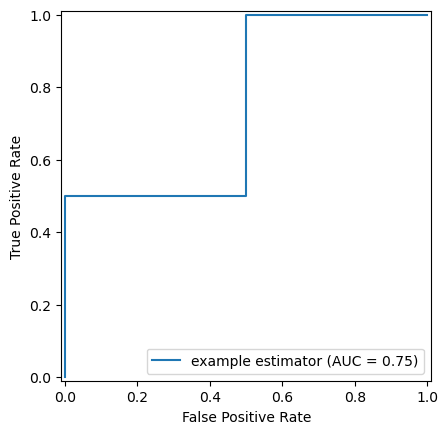

In [9]:


y = np.array([0, 0, 1, 1])
pred = np.array([0.1, 0.4, 0.35, 0.8])

fpr, tpr, thresholds = sklearn.metrics.roc_curve(y, pred)
roc_auc = sklearn.metrics.auc(fpr, tpr)
display = sklearn.metrics.RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc,
                                   estimator_name='example estimator')
display.plot()

plt.show()



# Einsetzen von einem Train/Test Split

Zur sinnvollen Evaluation muss der Datensatz in train und test geteilt werden. Diese muessen disjunk sein.
Auf den Trainingsdaten wird der Klassifikator trainiert, auf den Testddaten getestet. Geschieht dies nicht und der Klassifikator wird auf den selben Daten trainiert und getestet, hat die Evaluation keine Aussagekraft. Laut den Zahlen, wird ihr KLassifikator   hervorragend funktionieren. Die Generalisierungsfaehigkeit kann aber nicht getestet werden.

## Training auf dem Train-Subset

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train,y_test  = train_test_split(iris_dataset['data'][:,[0,1]],iris_dataset['target']) #random_state


knnTrainTest = KNeighborsClassifier(n_neighbors=1)
knnTrainTest.fit(X_train,y_train)



,n_neighbors,1
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


## Evaluation auf dem Test-Subset

In [11]:
pred=knnTrainTest.predict(X_test)
print(sklearn.metrics.accuracy_score(y_test,pred))


0.6842105263157895


In [12]:
#eval=sklearn.metrics.classification_report(iris_dataset.target,pred)
#print(eval)
#confMat=sklearn.metrics.confusion_matrix(iris_dataset.target, pred)
#print(confMat)

eval = sklearn.metrics.classification_report(y_test,pred)
print(eval)
confMat = sklearn.metrics.confusion_matrix(y_test,pred)
print(confMat)

              precision    recall  f1-score   support

           0       0.93      1.00      0.96        13
           1       0.50      0.42      0.45        12
           2       0.57      0.62      0.59        13

    accuracy                           0.68        38
   macro avg       0.67      0.68      0.67        38
weighted avg       0.67      0.68      0.68        38

[[13  0  0]
 [ 1  5  6]
 [ 0  5  8]]


# Kreuzvalidierung

Die Kreuzvalidierung eignet sich besonders fuer kleine Datensaetze. Der Datensatz wird in folds geteilt, beispielsweise 10 folds.
Der Klassifikator wird jeweils auf 9 folds trainiert, und auf dem verbleibenden getestet. Dieses Vorgehen wird so oft widerholt, bis jedes fold einmal zim Test verwendet wurde.

In [13]:
from sklearn.model_selection import cross_validate


model=KNeighborsClassifier(n_neighbors=1)

cv_results = cross_validate(model, X_train, y_train, cv=10)

print(cv_results['test_score'])
avg_score = np.average(cv_results['test_score'])

print("avg_score=%.2f%% " % ( avg_score * 100,))

[0.66666667 0.75       0.72727273 0.72727273 0.72727273 0.72727273
 0.81818182 0.63636364 0.90909091 0.72727273]
avg_score=74.17% 


## stratified


Durch die *stratified*  Variante der Kreuzvalidierung wird die statistische Gegebenheit des Datensatzes in den folds beigehalten. 
Das eignet sich besonders, wenn die Haeufigkeiten der Klassen nicht gleichverteilt sind. 


Das wird folgendermaßen in sklearn verwendet:

In [14]:
from sklearn.model_selection import StratifiedKFold


skf = StratifiedKFold(n_splits=10)
model=KNeighborsClassifier(n_neighbors=1)
accuracies=[]

for train_indices, test_indices in skf.split(X_train, y_train):
    #print("TRAIN:", train_indices, "TEST:", test_indices)
    model.fit(X_train[train_indices],y_train[train_indices])
    accuracies.append(model.score(X_train[test_indices],y_train[test_indices]))
    #print(accuracies[-1])

print("avg_score of stratified=%.2f%%" %(np.average(accuracies)*100))


avg_score of stratified=74.17%


## LeaveOneOut


Leave-one-out ist eine weitere Variante der Kreuzvalidierung. Hier wird jedes Sample einzeln betrachtet.
Jedes sample wird einmal zum Testen verwendet, alle anderen Sample werden zum Training benutzt.

In [15]:
from sklearn.model_selection import LeaveOneOut

loo = LeaveOneOut()
model=KNeighborsClassifier(n_neighbors=1)
accuracies=[]

for train_indices, test_indices in loo.split(X_train, y_train):
    #print("TRAIN:", train_indices, "TEST:", test_indices)
    model.fit(X_train[train_indices],y_train[train_indices])
    accuracies.append(model.score(X_train[test_indices],y_train[test_indices]))
    #print(accuracies[-1])

print("avg_score of stratified=%.2f%%" %(np.average(accuracies)*100))


avg_score of stratified=73.21%
